<a href="https://colab.research.google.com/github/jegillis323/MAT-422/blob/main/MAT422_Section_4_1_4_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 - Sections 4.1 and 4.2: Graphs and Graph Modeling

**Topics:** Graph Basics and Adjacency Representations, Degree and Neighbors, Graph Traversal, Graph and Graph Modeling

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

# Graph Basics and Adjacency Representations

In [20]:
nodes = ["Home", "School", "Library", "Store", "Park", "Cafe"]
edges = [("Home", "School"), ("Home", "Store"), ("School", "Cafe"), ("Library", "Park"), ("Store", "Park"), ("Park", "Cafe")]
index = {node: i for i, node in enumerate(nodes)}
adj = np.zeros((len(nodes), len(nodes)), dtype=int)
for u, v in edges:
    adj[index[u], index[v]] = 1
    adj[index[v], index[u]] = 1

print("Adjacency matrix:")
print(adj)

Adjacency matrix:
[[0 1 0 1 0 0]
 [1 0 0 0 0 1]
 [0 0 0 0 1 0]
 [1 0 0 0 1 0]
 [0 0 1 1 0 1]
 [0 1 0 0 1 0]]


My Explanation: In this system, there are six different locations that represent the nodes of the system and there are six different connections between the different nodes. The matrix lists each location as a row, with each column representing the other locations. If the two locations are connected, it will display a one and a zero if it is not connected.

#Degree and Neighbors

In [21]:
adj_list = {node: [] for node in nodes}

for u, v in edges:
    adj_list[u].append(v)
    adj_list[v].append(u)

degrees = {node: len(adj_list[node]) for node in nodes}

print("Adjacency list:")
for node in nodes:
    print(f"{node}: {adj_list[node]}")

print("\nDegrees:")
for node in nodes:
    print(f"{node}: {degrees[node]}")

max_degree = max(degrees.values())

most_connected = [node for node, deg in degrees.items() if deg == max_degree]

print("\nMost connected location(s):", ", ".join(most_connected))
print("Degree:", max_degree)

Adjacency list:
Home: ['School', 'Store']
School: ['Home', 'Cafe']
Library: ['Park']
Store: ['Home', 'Park']
Park: ['Library', 'Store', 'Cafe']
Cafe: ['School', 'Park']

Degrees:
Home: 2
School: 2
Library: 1
Store: 2
Park: 3
Cafe: 2

Most connected location(s): Park
Degree: 3


My Explanation: The adjacency list creates a list of each of the different neighbors, the adjacent locations, that one location has. The degrees show how many different locations are adjacent to it. The most connected also shows the location or locations with the most amount of connections to it, in this case being the Park with three connections.

#Graph Traversal

In [23]:
def bfs(start):
    seen = {start}
    order = []
    distances = {start: 0}
    queue = deque([start])

    while queue:
        node = queue.popleft()
        order.append(node)

        for neighbor in adj_list[node]:
            if neighbor not in seen:
                seen.add(neighbor)
                distances[neighbor] = distances[node] + 1
                queue.append(neighbor)

    return order, distances
order, distances = bfs("Home")

print("BFS order from Home:", order)
print("Distance from Home:", distances)

BFS order from Home: ['Home', 'School', 'Store', 'Cafe', 'Park', 'Library']
Distance from Home: {'Home': 0, 'School': 1, 'Store': 1, 'Cafe': 2, 'Park': 2, 'Library': 3}


My Explanation: Breadth-first search (BFS) is a search algorithm that goes through a tree of nodes and maps it out based on the connections between the nodes. From the BFS, we can see the order of the nodes as well as the distance from the starting point, which is the Home, the first node in the list in this case. We can see that the distance from the starting point is zero and the furthest point from the start is the Library with a distance of three.

Graph and Graph Modeling

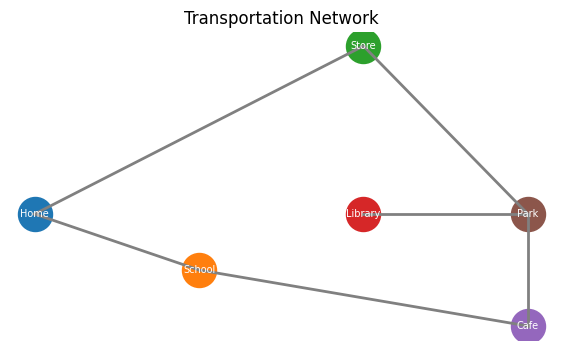

Accessibility scores:
Home: 0.67
School: 0.67
Library: 0.33
Store: 0.67
Park: 1.00
Cafe: 0.67


In [25]:
positions = {"Home":(0,2), "School":(1,1), "Store":(2,5), "Library":(2,2), "Cafe":(3,0), "Park":(3,2)}

plt.figure(figsize=(7, 4))

for u, v in edges:
    x = [positions[u][0], positions[v][0]]
    y = [positions[u][1], positions[v][1]]
    plt.plot(x, y, color="gray", linewidth=2)

for node, (x, y) in positions.items():
    plt.scatter(x, y, s=600)
    plt.text(x, y, node, ha="center", va="center", fontsize=7, color="white")

plt.axis("off")
plt.title("Transportation Network")
plt.show()

accessibility_scores = {}

max_degree = max(degrees.values())

for node in nodes:
    accessibility_scores[node] = degrees[node] / max_degree

print("Accessibility scores:")
for node, score in accessibility_scores.items():
    print(f"{node}: {score:.2f}")

My Explanation: The graph creates a visual for the different nodes and their connections. The accessiblity score is a metric that I created that expresses how many different connections a node has to the other nodes. An accessibility score of $1$ means that the location has three connections, a score of $\frac{2}{3}$ means that the location has two connections, and a score of $\frac{1}{3}$ means that the location only has one connection. No nodes have a score of $0$, but that would arise if there was a node with no connections to it.